Simulation examples for validation chapter


In [6]:
import time
import pymc as pm
import arviz as az
from scipy.stats import (
    norm, lognorm, uniform, cauchy, 
    poisson, nbinom, bernoulli,
    binom
)
from scipy.optimize import minimize

from matplotlib import pyplot as plt
import numpy as np
import seaborn as sns
from pathlib import Path

from bettercode.utils import save_fig_variants

IMAGE_DIR = Path('../../latex/figures')
CHAPTER = 9

In [7]:
rng = np.random.default_rng()
rng.uniform(size=10)

array([0.42025646, 0.52137824, 0.07493347, 0.52343279, 0.01278493,
       0.61056693, 0.19596189, 0.98677315, 0.18447967, 0.34556642])

Figure for uniform random variates

In [8]:
uniform_samples = rng.uniform(size=10000000)

Text(0, 0.5, 'Probability')

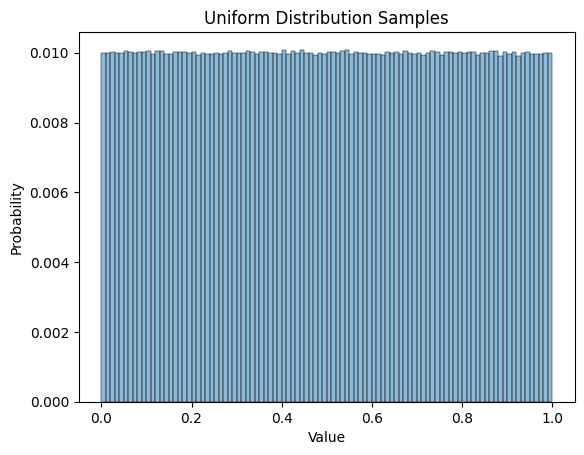

In [9]:

sns.histplot(uniform_samples, bins=100, alpha=0.5, stat='probability')
plt.title('Uniform Distribution Samples')
plt.xlabel('Value')
plt.ylabel('Probability')
# plt.savefig(IMAGE_DIR / 'uniform_distribution.png')

Create a plot of several different distributions.

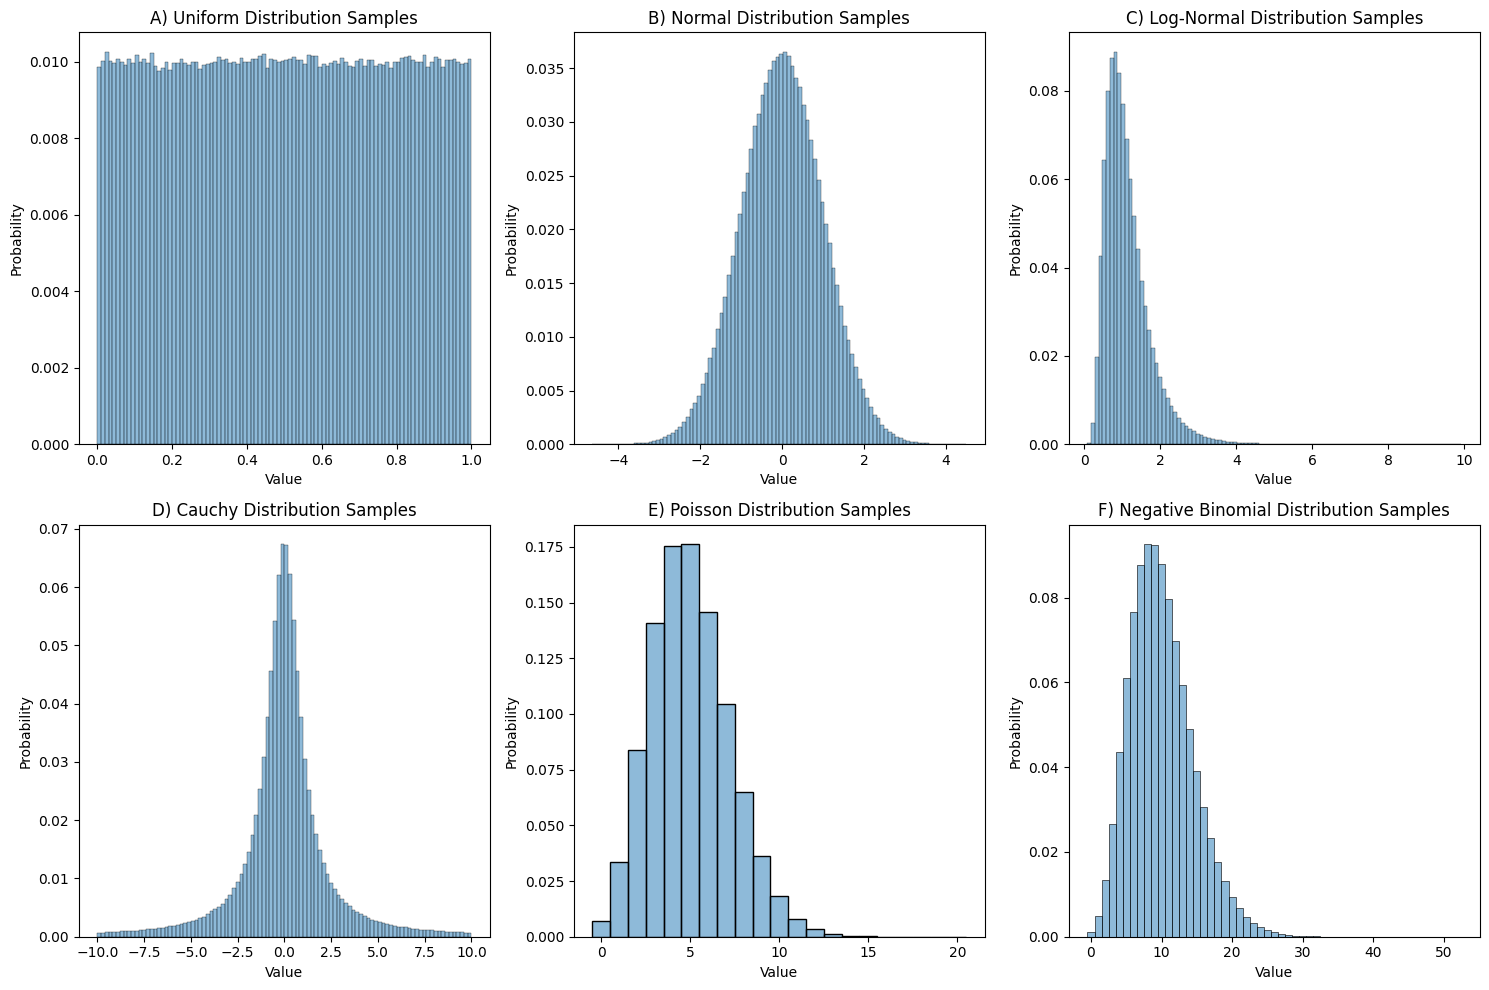

In [10]:

# Generate samples
n_samples = 1000000
distributions = {
    'Uniform': rng.uniform(size=n_samples),
    'Normal': rng.normal(size=n_samples),
    'Log-Normal': rng.lognormal(mean=0, sigma=0.5, size=n_samples),
    'Cauchy': rng.standard_cauchy(size=n_samples),
    'Poisson': rng.poisson(lam=5, size=n_samples),
    'Negative Binomial': rng.negative_binomial(n=10, p=0.5, size=n_samples)
}

# Panel labels
panel_labels = ['A', 'B', 'C', 'D', 'E', 'F']

# single-series histograms: just a neutral gray fill for the print variant
HIST_COLOR = {'color': None, 'gray': '0.5'}


def make_distplots(variant):
    color = HIST_COLOR[variant]
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.flatten()
    for idx, (name, samples) in enumerate(distributions.items()):
        ax = axes[idx]
        if name == 'Cauchy':
            # Cauchy has heavy tails, limit the range for visualization
            samples_trimmed = samples[(samples > -10) & (samples < 10)]
            sns.histplot(samples_trimmed, bins=100, alpha=0.5, stat='probability',
                         ax=ax, color=color)
        elif name in ['Poisson', 'Negative Binomial']:
            # Discrete distributions
            sns.histplot(samples, bins=30, alpha=0.5, stat='probability',
                         discrete=True, ax=ax, color=color)
        else:
            sns.histplot(samples, bins=100, alpha=0.5, stat='probability',
                         ax=ax, color=color)
        ax.set_title(f'{panel_labels[idx]}) {name} Distribution Samples')
        ax.set_xlabel('Value')
        ax.set_ylabel('Probability')
    fig.tight_layout()
    return fig


save_fig_variants(make_distplots, 'DistPlots', CHAPTER, IMAGE_DIR)
make_distplots("color")
plt.show()

In [11]:
# example draws from distributions mentioned in the text:

size = 1000
distributions = {
    'Bernoulli': rng.binomial(n=1, p=0.3, size=size),
    'Binomial': rng.binomial(n=10, p=0.5, size=size),
    'Normal': rng.normal(size=size),
    'Log-Normal': rng.lognormal(mean=0, sigma=0.5, size=size),
    'Uniform': rng.uniform(size=size),
    'Cauchy': rng.standard_cauchy(size=size),
    'Poisson': rng.poisson(lam=5, size=size),
    'Negative Binomial': rng.negative_binomial(n=10, p=0.5, size=size),
}

for name, samples in distributions.items():
    print(f"{name} samples:\n{samples[:10]}\n")  # Print first 10 samples for each distribution

Bernoulli samples:
[0 0 0 0 0 0 0 0 0 0]

Binomial samples:
[3 7 5 7 6 6 7 2 4 8]

Normal samples:
[-1.33634323  1.53457199 -1.42318853  1.70382764  0.79247613  1.58281247
 -0.19936977  2.06544576 -1.51517198  0.43912506]

Log-Normal samples:
[1.94302392 1.29644864 0.84881899 0.88081685 1.5685018  1.11745766
 1.46571725 0.84292316 0.7127911  0.25480001]

Uniform samples:
[0.50588824 0.94797615 0.77488299 0.89157857 0.38077351 0.82138148
 0.19993747 0.18855479 0.10404106 0.6238434 ]

Cauchy samples:
[ 1.6221508  -1.23019352 13.01646208  0.15360099  0.3176059   6.13014551
 -0.42413015 10.60978985  0.69562831 -0.04796889]

Poisson samples:
[2 7 5 5 4 7 2 2 2 4]

Negative Binomial samples:
[10 10 19  6  7  7 10 13  6  9]



In [12]:
### seeds
rng = np.random.default_rng(seed=42)
rng.uniform(size=4)



array([0.77395605, 0.43887844, 0.85859792, 0.69736803])

In [13]:
rng.uniform(size=4)

array([0.09417735, 0.97562235, 0.7611397 , 0.78606431])

In [14]:
rng2 = np.random.default_rng(seed=42)
rng2.uniform(size=4)

array([0.77395605, 0.43887844, 0.85859792, 0.69736803])

In [15]:
rng2.uniform(size=4)    

array([0.09417735, 0.97562235, 0.7611397 , 0.78606431])

## estimating parameters

In [16]:
sample_size = 1000

# set up numpy random state
random_state = np.random.default_rng(42)

# True population parameters (using standard normal)
true_mean = 0
true_sd = 1

# take sample
normal_samples = norm.rvs(loc=true_mean, scale=true_sd, size=sample_size, random_state=random_state)


In [17]:
# compute mean by hand
start_time = time.time()
sample_mean = np.sum(normal_samples) / sample_size
assert sample_mean == np.mean(normal_samples)

# compute sd by hand
squared_diffs = (normal_samples - sample_mean) ** 2
sample_variance = np.sum(squared_diffs) / (sample_size - 1)
sample_sd = np.sqrt(sample_variance)
assert sample_sd == np.std(normal_samples, ddof=1)
elapsed_time_cf = time.time() - start_time
print(elapsed_time_cf)


0.0001780986785888672


In [18]:
# compute confidence interval using t distribution
from scipy.stats import t

# Calculate 95% confidence interval
confidence_level = 0.95
alpha = 1 - confidence_level
degrees_of_freedom = sample_size - 1

# Get the critical t-value
t_critical = t.ppf(1 - alpha/2, degrees_of_freedom)

# Calculate standard error
standard_error = sample_sd / np.sqrt(sample_size)

# Calculate margin of error
margin_of_error = t_critical * standard_error

# Calculate confidence interval
ci_lower = sample_mean - margin_of_error
ci_upper = sample_mean + margin_of_error

print(f"Sample mean: {sample_mean:.5f}")
print(f"Sample SD: {sample_sd:.5f}")
print(f"Standard error: {standard_error:.5f}")
print(f"t-critical value (df={degrees_of_freedom}): {t_critical:.5f}")
print(f"95% Confidence Interval: [{ci_lower:.5f}, {ci_upper:.5f}]")

Sample mean: -0.02889
Sample SD: 0.98922
Standard error: 0.03128
t-critical value (df=999): 1.96234
95% Confidence Interval: [-0.09028, 0.03249]


In [19]:
# simulate to confirm that the CI captures the true population mean 95% of the time in new samples from the same distribution



# Simulation parameters
n_simulations = 100000
confidence_level = 0.95
alpha = 1 - confidence_level
random_state = np.random.default_rng(42)

# Track how many times the CI captures the true mean
captures = 0

# Run simulations
for i in range(n_simulations):
    # Draw a new sample from the population
    sample = norm.rvs(loc=true_mean, scale=true_sd, 
        size=sample_size, random_state=random_state)
    
    # Calculate sample statistics
    sample_mean_sim = np.mean(sample)
    sample_sd_sim = np.std(sample, ddof=1)
    
    # Calculate confidence interval
    df = sample_size - 1
    t_crit = t.ppf(1 - alpha/2, df)
    se = sample_sd_sim / np.sqrt(sample_size)
    margin = t_crit * se
    
    ci_low = sample_mean_sim - margin
    ci_high = sample_mean_sim + margin
    
    # Check if CI captures the true mean
    if ci_low <= true_mean <= ci_high:
        captures += 1

# Calculate coverage rate
coverage_rate = captures / n_simulations

print(f"Simulation results:")
print(f"Number of simulations: {n_simulations}")
print(f"Sample size per simulation: {sample_size}")
print(f"True population mean: {true_mean}")
print(f"Confidence level: {confidence_level * 100}%")
print(f"\nCoverage rate: {coverage_rate:.4f} ({coverage_rate * 100:.2f}%)")
print(f"Number of times CI captured true mean: {captures} out of {n_simulations}")
print(f"\nExpected coverage: {confidence_level * 100}%")
print(f"Difference from expected: {(coverage_rate - confidence_level) * 100:.2f}%")

Simulation results:
Number of simulations: 100000
Sample size per simulation: 1000
True population mean: 0
Confidence level: 95.0%

Coverage rate: 0.9497 (94.97%)
Number of times CI captured true mean: 94966 out of 100000

Expected coverage: 95.0%
Difference from expected: -0.03%


In [20]:
## Bootstrap estimate of confidence interval using scipy.stats.bootstrap

from scipy.stats import bootstrap
res = bootstrap((normal_samples,), np.mean, confidence_level=0.95,      
    n_resamples=10000, method='BCa', random_state=random_state)

print(f'Bootstrap 95% CI for mean: '
    f'[{res.confidence_interval.low:.5f}, '
    f'{res.confidence_interval.high:.5f}]')
print(f'CI based on t-distribution: [{ci_lower:.5f}, {ci_upper:.5f}]')

Bootstrap 95% CI for mean: [-0.09161, 0.03069]
CI based on t-distribution: [-0.09028, 0.03249]


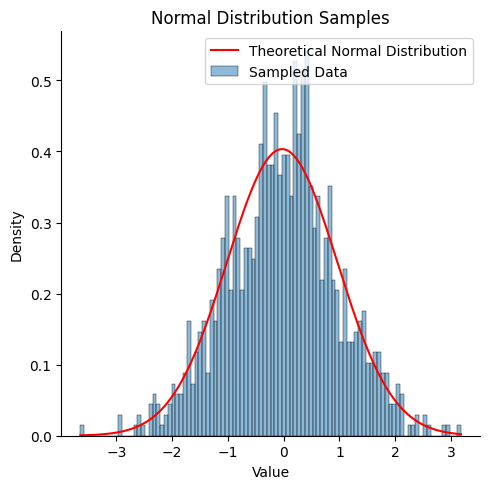

In [21]:
# theoretical pdf overlay for the normal samples
x = np.linspace(min(normal_samples), max(normal_samples), 1000)
pdf = (1 / (sample_sd * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - sample_mean) / sample_sd) ** 2)

# histogram and curve differ by fill vs. line, so gray just needs a neutral fill
# and a black curve
NORMAL_STYLE = {'color': {'hist': None, 'curve': 'red'},
                'gray': {'hist': '0.6', 'curve': 'black'}}


def make_normaldist(variant):
    style = NORMAL_STYLE[variant]
    hist_kwargs = {'bins': 100, 'alpha': 0.5, 'stat': 'density'}
    if style['hist'] is not None:
        hist_kwargs['color'] = style['hist']
    g = sns.displot(normal_samples, **hist_kwargs)
    ax = g.ax
    ax.plot(x, pdf, color=style['curve'])
    ax.set_title('Normal Distribution Samples')
    ax.set_xlabel('Value')
    ax.set_ylabel('Density')
    ax.legend(['Theoretical Normal Distribution', 'Sampled Data'])
    g.figure.tight_layout()
    return g.figure


save_fig_variants(make_normaldist, 'NormalDist', CHAPTER, IMAGE_DIR)
make_normaldist("color")
plt.show()

In [22]:
# do a grid search for mean and sd to find best fit
def normal_params_grid_search(data, mean_grid=None, sd_grid=None):
    if mean_grid is None:
        mean_grid = np.linspace(-1, 1, 1000)
    if sd_grid is None:
        sd_grid = np.linspace(0.5, 1.5, 1000)

    log_likelihoods = np.zeros((len(mean_grid), len(sd_grid)))
    for i, mu in enumerate(mean_grid):
        for j, sd in enumerate(sd_grid):
            # compute log likelihood for current mu and sd
            log_likelihoods[i, j] = norm.logpdf(data, loc=mu, scale=sd).sum()


    # find the parameters that maximize the log likelihood
    max_idx = np.unravel_index(np.argmax(log_likelihoods), log_likelihoods.shape)
    best_mean = mean_grid[max_idx[0]]
    best_sd = sd_grid[max_idx[1]]

    return best_mean, best_sd, log_likelihoods, mean_grid, sd_grid

start_time = time.time()
best_mean, best_sd, log_likelihoods, mean_grid, sd_grid = normal_params_grid_search(normal_samples)
elapsed_time_grid = time.time() - start_time




In [23]:
best_fit_ll = norm.logpdf(normal_samples, loc=best_mean, scale=best_sd).sum()
pop_sd = np.std(normal_samples, ddof=0)
sample_sd = np.std(normal_samples, ddof=1)

sample_ll = norm.logpdf(normal_samples, loc=sample_mean, 
    scale=pop_sd).sum()

print(f"Execution time: {elapsed_time_grid:.4f} seconds")
print(f'Execution time versus closed form: {elapsed_time_grid/elapsed_time_cf} times slower')
print(f"Best fit mean: {best_mean:0.4f}, Best fit sd: {best_sd:0.4f}, loglik: {best_fit_ll:0.4f}")
print(f"Sample mean: {sample_mean:0.4f}, Population sd: {pop_sd:0.4f}, loglik: {sample_ll:0.4f}")


Execution time: 25.3249 seconds
Execution time versus closed form: 142195.63052208835 times slower
Best fit mean: -0.0290, Best fit sd: 0.9885, loglik: -1407.5969
Sample mean: -0.0289, Population sd: 0.9887, loglik: -1407.5968


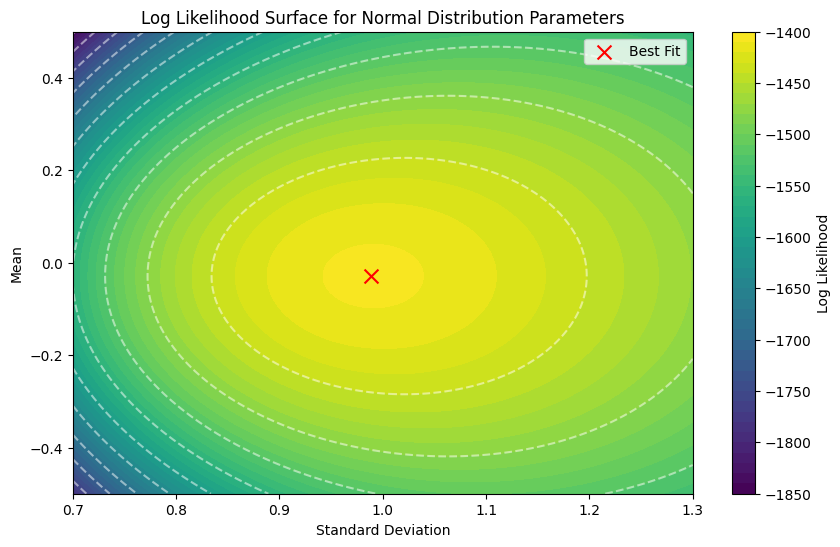

In [24]:
# plot the log likelihood surface using a broader range of values
mean_grid = np.linspace(-.5, .5, 1000)
sd_grid = np.linspace(0.7, 1.3, 1000)
best_mean_vis, best_sd_vis, log_likelihoods_vis, mean_grid, sd_grid = normal_params_grid_search(normal_samples, mean_grid=mean_grid, sd_grid=sd_grid)

plt.figure(figsize=(10, 6))
X, Y = np.meshgrid(sd_grid, mean_grid)
plt.contourf(X, Y, log_likelihoods_vis, levels=50, cmap='viridis')
plt.colorbar(label='Log Likelihood')
plt.scatter(best_sd_vis, best_mean_vis, color='red', label='Best Fit', marker='x', s=100)
plt.xlabel('Standard Deviation')
plt.ylabel('Mean')
plt.title('Log Likelihood Surface for Normal Distribution Parameters')
plt.legend()
# add contour lines
plt.contour(X, Y, log_likelihoods_vis, levels=10, colors='white', alpha=0.5)
plt.savefig(IMAGE_DIR / 'normal_log_likelihood_surface.png', dpi=150, bbox_inches='tight')
plt.show()


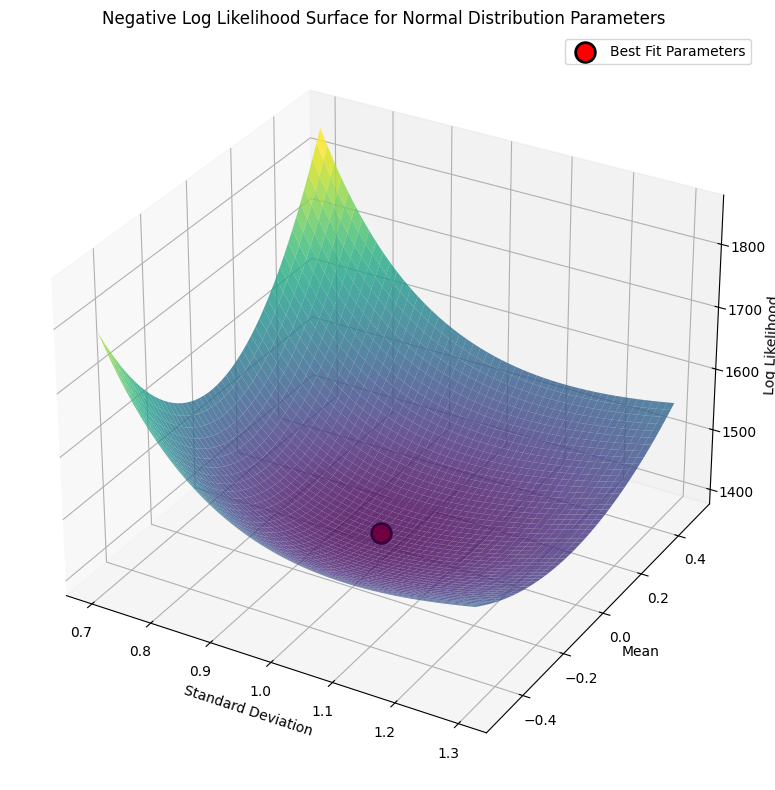

In [25]:
# generate a surface plot of the log likelihoods, in color (web) and grayscale (print)
from mpl_toolkits.mplot3d import Axes3D
X, Y = np.meshgrid(sd_grid, mean_grid)
neg_ll = -1 * log_likelihoods_vis

# gray: Greys surface, black contours, white-filled black-edged best-fit marker
SURF_STYLE = {
    'color': {'cmap': 'viridis', 'contour': 'blue', 'point': 'red', 'point_edge': 'black'},
    'gray': {'cmap': 'Greys', 'contour': 'black', 'point': 'white', 'point_edge': 'black'},
}


def make_gridsearch(variant):
    style = SURF_STYLE[variant]
    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_subplot(111, projection='3d')
    ax.plot_surface(X, Y, neg_ll, cmap=style['cmap'], edgecolor='none', alpha=0.8)
    ax.set_xlabel('Standard Deviation')
    ax.set_ylabel('Mean')
    ax.set_zlabel('Log Likelihood')
    ax.set_title('Negative Log Likelihood Surface for Normal Distribution Parameters')
    # contour lines on the bottom plane
    ax.contour(X, Y, neg_ll, zdir='z', offset=np.min(log_likelihoods_vis),
               levels=10, colors=style['contour'], alpha=0.5)
    # best-fit parameter values on the bottom plane
    ax.scatter(best_sd_vis, best_mean_vis, np.min(neg_ll), color=style['point'],
               s=200, marker='o', edgecolors=style['point_edge'], linewidths=2,
               label='Best Fit Parameters', zorder=10)
    ax.legend()
    fig.tight_layout()
    return fig


save_fig_variants(make_gridsearch, 'gridsearch', CHAPTER, IMAGE_DIR)
make_gridsearch("color")
plt.show()

In [26]:
# use optimization to find best fit parameters

def negative_log_likelihood(params, data):
    """Negative log likelihood function to minimize"""
    mu, sd = params
    if sd <= 0:  # ensure sd is positive
        return np.inf
    return -norm.logpdf(data, loc=mu, scale=sd).sum()

# initial guess
initial_params = [0, 1]

start_time = time.time()
result = minimize(negative_log_likelihood, initial_params, args=(normal_samples,), 
                  method='Nelder-Mead')
elapsed_time_opt = time.time() - start_time

opt_mean, opt_sd = result.x
opt_ll = -result.fun

print(f"Optimization time: {elapsed_time_opt:.4f} seconds")
print(f'Optimization time versus grid search: {elapsed_time_grid/elapsed_time_opt:.4f} times faster')
print(f'Optimization time versus closed form: {elapsed_time_opt/elapsed_time_cf:.4f} times slower')
print(f"Optimized mean: {opt_mean:0.5f}, Optimized sd: {opt_sd:0.5f}, loglik: {opt_ll:0.5f}")
print(f"Sample mean: {sample_mean:0.5f}, Population sd: {pop_sd:0.5f}, loglik: {sample_ll:0.5f}")


Optimization time: 0.0119 seconds
Optimization time versus grid search: 2131.3937 times faster
Optimization time versus closed form: 66.7149 times slower
Optimized mean: -0.02889, Optimized sd: 0.98874, loglik: -1407.59681
Sample mean: -0.02889, Population sd: 0.98872, loglik: -1407.59681


In [27]:
# use really bad initial guesses
initial_params = [10000, 10000]

start_time = time.time()
result = minimize(negative_log_likelihood, initial_params, args=(normal_samples,), 
                  method='Nelder-Mead')
elapsed_time_opt_bad = time.time() - start_time

opt_mean, opt_sd = result.x
opt_ll = -result.fun

print(f"Optimization time: {elapsed_time_opt_bad:.4f} seconds")
print(f'Optimization time versus grid search: {elapsed_time_grid/elapsed_time_opt_bad:.4f} times faster')
print(f'Optimization time versus closed form: {elapsed_time_opt_bad/elapsed_time_cf:.4f} times slower')
print(f"Optimized mean: {opt_mean:0.5f}, Optimized sd: {opt_sd:0.5f}, loglik: {opt_ll:0.5f}")
print(f"Sample mean: {sample_mean:0.5f}, Population sd: {pop_sd:0.5f}, loglik: {sample_ll:0.5f}")


Optimization time: 0.0055 seconds
Optimization time versus grid search: 4626.3125 times faster
Optimization time versus closed form: 30.7363 times slower
Optimized mean: -0.02893, Optimized sd: 0.98877, loglik: -1407.59682
Sample mean: -0.02889, Population sd: 0.98872, loglik: -1407.59681


In [28]:
# create a version with boundaries on sd parameter in the optimzation
from scipy.optimize import Bounds

# Define bounds: mean unbounded, sd must be positive
bounds = Bounds(lb=[-np.inf, 0], ub=[np.inf, np.inf])

# use really bad initial guesses
initial_params = [0, 1]

start_time = time.time()
result = minimize(negative_log_likelihood, initial_params, args=(normal_samples,), 
                  method='L-BFGS-B', bounds=bounds)
elapsed_time_opt_bounded = time.time() - start_time

opt_mean, opt_sd = result.x
opt_ll = -result.fun

print(f"Optimization time with bounds: {elapsed_time_opt_bounded:.4f} seconds")
print(f'Optimization time versus grid search: {elapsed_time_grid/elapsed_time_opt_bounded:.4f} times faster')
print(f'Optimization time versus closed form: {elapsed_time_opt_bounded/elapsed_time_cf:.4f} times slower')
print(f"Optimized mean: {opt_mean:0.5f}, Optimized sd: {opt_sd:0.5f}, loglik: {opt_ll:0.5f}")
print(f"Sample mean: {sample_mean:0.5f}, Population sd: {pop_sd:0.5f}, loglik: {sample_ll:0.5f}")

Optimization time with bounds: 0.0056 seconds
Optimization time versus grid search: 4497.4230 times faster
Optimization time versus closed form: 31.6171 times slower
Optimized mean: -0.02889, Optimized sd: 0.98872, loglik: -1407.59681
Sample mean: -0.02889, Population sd: 0.98872, loglik: -1407.59681


### Bayesian estimation

In [29]:


start_time = time.time()

# Bayesian estimation using PyMC
with pm.Model() as model:
    # Priors for unknown model parameters
    mu = pm.Normal('mu', mu=0, sigma=1000)  # Prior for mean
    sigma = pm.HalfNormal('sigma', sigma=100)  # Prior for standard deviation (must be positive)
    
    # Likelihood (sampling distribution) of observations
    likelihood = pm.Normal('likelihood', mu=mu, sigma=sigma, observed=normal_samples)
    
    # Posterior sampling
    trace = pm.sample(10000, tune=1000, return_inferencedata=True, random_seed=42)

# Extract posterior estimates
posterior_mean = trace.posterior['mu'].mean().values
posterior_sd = trace.posterior['sigma'].mean().values

# extract highest density interval
hdi = az.hdi(trace, hdi_prob=0.95)
hdi_values = hdi.mu.values

elapsed_time_bayes = time.time() - start_time


print(f"Bayesian estimation time: {elapsed_time_bayes:.4f} seconds")
print(f'Bayesian time versus optimization: {elapsed_time_bayes/elapsed_time_opt:.4f} times slower')
print(f'Bayesian time versus grid search: {elapsed_time_bayes/elapsed_time_grid:.4f} times slower')
print(f"Posterior mean: {posterior_mean:.5f}, Posterior sd: {posterior_sd:.5f}")
print(f"Sample mean: {sample_mean:.5f}, Sample sd: {sample_sd:.5f}")
print(f'95% HDI values: {hdi_values}')
print(f'95% CI based on t-distribution: [{ci_lower:.5f}, {ci_upper:.5f}]')

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu, sigma]


Output()

Sampling 4 chains for 1_000 tune and 10_000 draw iterations (4_000 + 40_000 draws total) took 1 seconds.


Bayesian estimation time: 2.5060 seconds
Bayesian time versus optimization: 210.9095 times slower
Bayesian time versus grid search: 0.0990 times slower
Posterior mean: -0.02895, Posterior sd: 0.99033
Sample mean: -0.02889, Sample sd: 0.98922
95% HDI values: [-0.08993754  0.03335397]
95% CI based on t-distribution: [-0.09028, 0.03249]


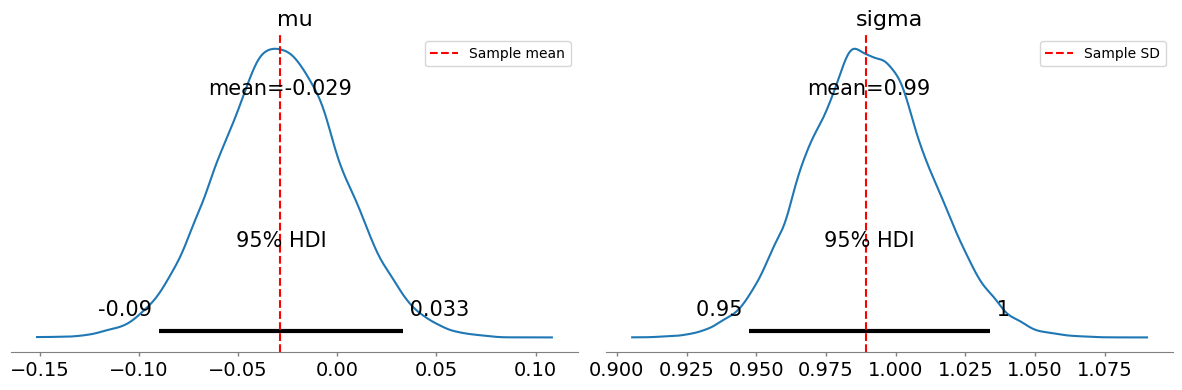

In [30]:
# Visualize posterior distributions, in color (web) and grayscale (print)
# arviz draws the posterior in a default color; the reference line stays a dashed
# vertical, black in the print variant
POST_STYLE = {'color': {'ref': 'red'}, 'gray': {'ref': 'black'}}


def make_bayesposterior(variant):
    style = POST_STYLE[variant]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    az.plot_posterior(trace, var_names=['mu'], ax=axes[0], hdi_prob=0.95)
    axes[0].axvline(sample_mean, color=style['ref'], linestyle='--', label='Sample mean')
    axes[0].legend()

    az.plot_posterior(trace, var_names=['sigma'], ax=axes[1], hdi_prob=0.95)
    axes[1].axvline(sample_sd, color=style['ref'], linestyle='--', label='Sample SD')
    axes[1].legend()

    fig.tight_layout()
    return fig


save_fig_variants(make_bayesposterior, 'BayesPosterior', CHAPTER, IMAGE_DIR)
make_bayesposterior("color")
plt.show()